# Cell-type deconvolution of Visium spots with RCTD

We grow one tumor, cut the resected tumor in two, and measure one half by single-cell RNA sequencing (scRNA-seq) and a section of the other half by 10x Visium.
We then deconvolve the Visium spots into cell types with RCTD ([Cable et al. 2022](https://github.com/dmcable/spacexr)), using the scRNA-seq data of the same tumor as the reference, and compare its cell-type proportions per spot with the true proportions, which the answer key holds, since `iscc` tracks the cells in each spot.

RCTD runs in its own conda environment, `iscc-rctd`, from a short R script that the notebook writes and runs with that environment's `Rscript`.

In [1]:
import os
import tempfile
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from iscc.data import Visium, scRNA
from iscc.data.human import HUMAN_VISIUM_KAPPA, HumanGenomeLayer, arm_genome, write_scrna, write_visium
from iscc.integrations import biological_types
from iscc.sample import Resection
from iscc.tumor import GenotypeTumor

CONFIG = os.path.abspath("tutorial_config.yaml")
RSCRIPT = os.path.expanduser("~/miniconda3/envs/iscc-rctd/bin/Rscript")
os.chdir(tempfile.mkdtemp())        # the data and the tool's outputs go to a scratch directory
warnings.filterwarnings("ignore", message="max_cells=")   # we dissociate a fixed number of cells on purpose

## The tumor

We grow the tutorial configuration to 25,000 cancer cells, with two changes that put its data on the human genes.
The genome that [`arm_genome`](../reference/arm_genome.md) builds has one segment per chromosome arm, keeping the number of growth genes of the configuration, about 6,000, and its 240 drivers, so that [`HumanGenomeLayer`](../reference/HumanGenomeLayer.md) can map each segment onto its chromosome arm.
The epithelium is the cell of origin, so that cancer cells share the expression baseline of normal epithelial cells and differ from them only by what evolution did to them.

25,023 cancer cells after 247 generations


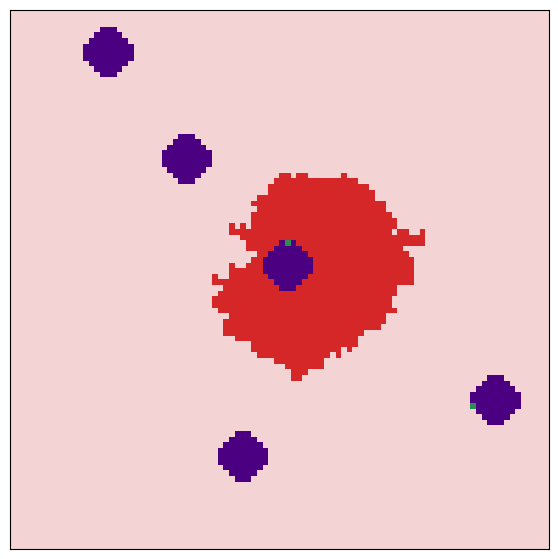

In [2]:
config = yaml.safe_load(open(CONFIG))
genome = arm_genome(total_genes=6000, driver_scale=0.4)
config["genome_params"] = genome["genome_params"]
config["selection_params"].update(genome["selection_params"])
with open("config.yaml", "w") as f:
    yaml.safe_dump(config, f)

tumor = GenotypeTumor(config="config.yaml", seed=1, expression_params={"cell_of_origin": "epithelial"})
tumor.grow(n_steps=3000, target_cancer=25_000)
print(f"{tumor.get_cancer_size():,} cancer cells after {tumor.time:.0f} generations")
tumor.plot_tissue();

## Two samples of one resection

[`Resection`](../reference/Resection.md) cuts the specimen in the plane into two halves, as a pathologist would.
We dissociate one half into about 3,000 cells for scRNA-seq and cut a thin section of the other half for Visium, keeping half of the depth of each deme, so that the section is about one cell layer thick.
The configuration caps every sample at 8,000 cells (`max_cells`), so we raise the cap for the section, letting its thickness set the number of cells.

In [3]:
specimen = Resection(tumor)
half_dissociated, half_sectioned = specimen.bisect(frac=0.5)
cells = specimen.dissociate(half_dissociated, max_cells=3000)
section = specimen.slice(half_sectioned, depth_frac=0.5, max_cells=100_000, layers="visium")
for name, sample in [("dissociated", cells), ("section", section)]:
    types = pd.Series(biological_types(sample["cell_type"].iloc[:, 0])).value_counts()
    print(f"{name:>12}: {types.sum():,} cells,", types.to_dict())

 dissociated: 3,064 cells, {'stromal': 2228, 'cancer': 613, 'epithelial': 223}
     section: 28,396 cells, {'stromal': 20164, 'cancer': 7244, 'epithelial': 988}


We measure the section with [`Visium`](../reference/Visium.md) over a spot grid that covers the field, and the dissociated cells with the 10x Genomics preset of [`scRNA`](../reference/scRNA.md), both over the human genes.
Visium takes the count concentration calibrated for the human genes (`HUMAN_VISIUM_KAPPA`), and scRNA leaves out the dropout curve of its preset, which is set for the 6,000 growth genes and, spread over the 35,061 human genes, would make the cells much sparser than real 10x data.
[`write_visium`](../reference/write_visium.md) and [`write_scrna`](../reference/write_scrna.md) write the data as Space Ranger and Cell Ranger output, with the answer key in a separate `truth` folder that no tool reads.

In [4]:
layer = HumanGenomeLayer(tumor)
expression = layer.expression(tumor)
visium = Visium(seed=1, kappa=HUMAN_VISIUM_KAPPA).run(section, grid_side=tumor.grid_size, gene_lift=expression)
write_visium("visium", visium, layer, tumor=tumor)
rna = scRNA(protocol="10x", n_cells=len(cells["cell_exp"]), dropout_mid=0.0, seed=1).run(cells, gene_lift=expression)
write_scrna("scrna", rna, layer, cells, tumor=tumor)

in_tissue = visium.obs["n_cells"] > 0
print(f"Visium: {in_tissue.sum():,} spots over the tissue, a median of {visium.obs.loc[in_tissue, 'n_cells'].median():.0f} "
      f"cells and {visium.obs.loc[in_tissue, 'n_counts'].median():,.0f} UMIs per spot")
print(f"scRNA: {rna.obs.shape[0]:,} cells, a median of {rna.obs['n_counts'].median():,.0f} UMIs per cell")

Visium: 1,321 spots over the tissue, a median of 10 cells and 19,918 UMIs per spot
scRNA: 3,064 cells, a median of 3,690 UMIs per cell


RCTD needs the cell type of each reference cell.
A user annotates the microenvironment from marker genes and tells cancer cells from normal epithelial cells by copy number, for example with inferCNV as in [the scRNA copy-number tutorial](tool_scrna_cnv.ipynb).
Here we take the cell types from the answer key, which stands for an annotation without errors, and leave out the doublets.

In [5]:
cell_truth = pd.read_csv("scrna/truth/cells.tsv", sep="\t", index_col="barcode", dtype={"genotype": str})
cell_truth["cell_type"] = biological_types(cell_truth["genotype"])
cell_truth.loc[~cell_truth["is_doublet"], ["cell_type"]].to_csv("reference_cell_types.csv")
cell_truth.loc[~cell_truth["is_doublet"], "cell_type"].value_counts().to_dict()

{'stromal': 2121, 'cancer': 580, 'epithelial': 210}

## RCTD

The script below runs spacexr's standard workflow, which builds a `Reference` from the annotated scRNA-seq counts and a `SpatialRNA` from the Visium counts and the spot positions, and runs `run.RCTD`.
RCTD runs in full mode, which fits any mixture of cell types in a spot, as spacexr's documentation recommends for technologies with large spots such as Visium.
It runs on one core (`max_cores = 1`), since its parallel workers failed intermittently on our laptop and one core is about as fast at this size, and every other setting is the default.
The counts are read from the Cell Ranger and Space Ranger matrix directories with the Matrix package.

In [6]:
%%writefile run_rctd.R
suppressMessages({library(spacexr); library(Matrix)})

read_10x <- function(dir) {           # a filtered_feature_bc_matrix directory of Cell Ranger or Space Ranger
  counts <- readMM(file.path(dir, "matrix.mtx.gz"))
  rownames(counts) <- make.unique(read.delim(file.path(dir, "features.tsv.gz"), header = FALSE)[[2]])
  colnames(counts) <- read.delim(file.path(dir, "barcodes.tsv.gz"), header = FALSE)[[1]]
  as(counts, "CsparseMatrix")
}

ref_counts <- read_10x("scrna/outs/filtered_feature_bc_matrix")
annotation <- read.csv("reference_cell_types.csv", row.names = 1)
ref_counts <- ref_counts[, rownames(annotation)]
cell_types <- factor(annotation$cell_type, levels = sort(unique(annotation$cell_type)))
names(cell_types) <- rownames(annotation)
reference <- Reference(ref_counts, cell_types)

spot_counts <- read_10x("visium/outs/filtered_feature_bc_matrix")
positions <- read.csv("visium/outs/spatial/tissue_positions.csv", row.names = 1)
coords <- positions[colnames(spot_counts), c("pxl_col_in_fullres", "pxl_row_in_fullres")]
colnames(coords) <- c("x", "y")
puck <- SpatialRNA(coords, spot_counts)

rctd <- create.RCTD(puck, reference, max_cores = 1)
rctd <- run.RCTD(rctd, doublet_mode = "full")
proportions <- as.matrix(normalize_weights(rctd@results$weights))
write.csv(proportions, "rctd_proportions.csv")
cat(sprintf("spacexr %s: %d spots and %d cell types\n", packageVersion("spacexr"), nrow(proportions), ncol(proportions)))

Writing run_rctd.R


In [7]:
!{RSCRIPT} run_rctd.R > rctd.log 2>&1; tail -n 1 rctd.log

spacexr 2.2.1: 1321 spots and 3 cell types


## RCTD recovers the cancer and stromal proportions and confuses normal epithelium with cancer

We read the true proportion of each cell type in each spot from the cells that the answer key lists for the spot.
We compare RCTD's proportions with these over the spots RCTD fitted, through the Pearson correlation and the mean absolute error for each cell type.

In [8]:
spots = pd.read_csv("visium/truth/spots.tsv", sep="\t", index_col="barcode", dtype={"genotypes": str})
spot_cells = spots["genotypes"].dropna().str.split(",").explode()
true_prop = pd.crosstab(spot_cells.index, biological_types(spot_cells), normalize="index")
rctd = pd.read_csv("rctd_proportions.csv", index_col=0)
true_prop = true_prop.reindex(index=rctd.index, columns=rctd.columns, fill_value=0.0)

pd.DataFrame({"mean true proportion": true_prop.mean(), "mean RCTD proportion": rctd.mean(),
              "Pearson r": rctd.corrwith(true_prop),
              "mean absolute error": (rctd - true_prop).abs().mean()}).round(2)

,mean true proportion,mean RCTD proportion,Pearson r,mean absolute error
cancer,0.10,0.11,0.97,0.02
epithelial,0.01,0.02,0.73,0.02
stromal,0.89,0.87,1.00,0.02


The maps show the true proportion of each cell type per spot (top) and RCTD's (bottom).

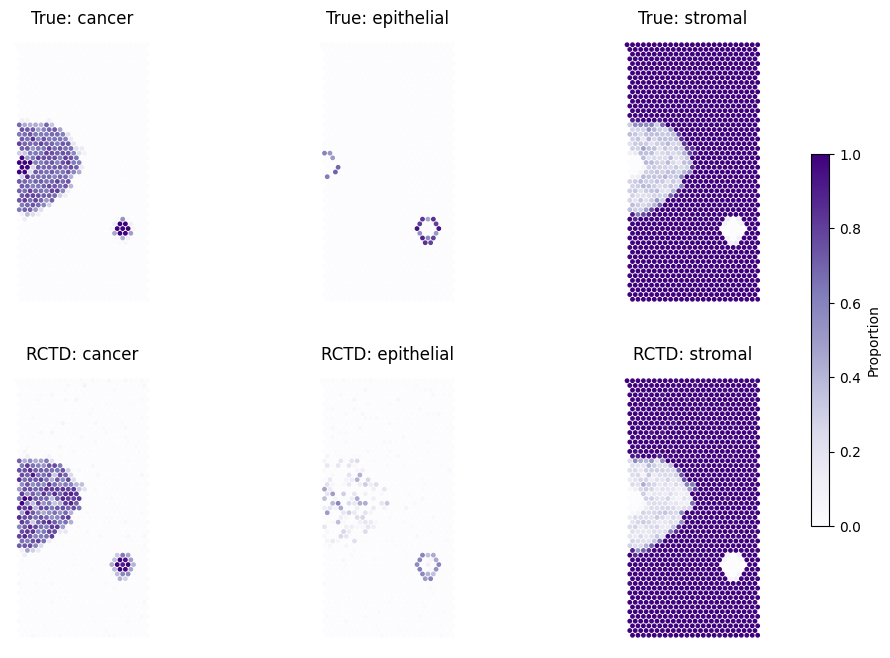

In [9]:
xy = pd.read_csv("visium/outs/spatial/tissue_positions.csv", index_col=0).loc[rctd.index]
fig, axes = plt.subplots(2, len(rctd.columns), figsize=(4 * len(rctd.columns), 8))
for row, (label, values) in enumerate([("True", true_prop), ("RCTD", rctd)]):
    for col, cell_type in enumerate(rctd.columns):
        ax = axes[row, col]
        im = ax.scatter(xy["pxl_col_in_fullres"], xy["pxl_row_in_fullres"], c=values[cell_type], s=6,
                        cmap="Purples", vmin=0, vmax=1)
        ax.set_title(f"{label}: {cell_type}")
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.02, label="Proportion")
plt.show()

RCTD's proportions followed the true ones closely for cancer cells and stromal cells, with Pearson correlations of 0.97 and 1.00 and mean absolute errors of 0.02.
For normal epithelial cells the correlation was lower (0.73), and the maps show RCTD giving small epithelial proportions to spots inside the tumor, where the section holds almost no normal epithelial cells.
In principle, we expect this confusion, since cancer cells share the expression baseline of normal epithelial cells, the cell of origin of the tumor, and differ from them only by copy number, mutations and programs.
The cell types of the reference here have no annotation errors, so an annotation from a copy-number caller would in principle make the two types harder to separate.

## Making the benchmark harder or easier

The number of cells per spot is set by the thickness of the section (`depth_frac` of [`Resection.slice`](../reference/Resection.md)) and by the spot size of [`Visium`](../reference/Visium.md) (`spot_radius`), and more cells per spot make the mixtures harder to resolve.
Two technical artifacts of Visium, lateral diffusion (`diffusion_sigma`) and spot swapping (`bleed_rate`, `bleed_distal`, `bleed_sigma`), are off by default, and switching them on mixes the counts of neighboring spots, as [Shape the data](03_shape_the_data.ipynb) shows.
A reference from a different region of the tumor, or with fewer cells of a type, makes the reference less representative of the section, and an annotation with errors, for example cancer cells called from copy number, makes the cancer and epithelial profiles less distinct.
The size of the tumor (`target_cancer`) sets how much of the section is cancer, and a more unstable genome (`mutation_rate` and `wgd_rate` in the configuration, see [`GenotypeTumor`](../reference/GenotypeTumor.md)) makes cancer cells differ more from normal epithelial cells.